In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from pandas.plotting import scatter_matrix
from sklearn.preprocessing import scale
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn import preprocessing
import copy

In [ ]:
import pandas as pd
df=pd.read_csv('CarPrice.csv')

In [ ]:
display(df.head())

,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,...,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
0,1,3,alfa-romero giulia,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495.0
1,2,3,alfa-romero stelvio,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500.0
2,3,1,alfa-romero Quadrifoglio,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500.0
3,4,2,audi 100 ls,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950.0
4,5,2,audi 100ls,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450.0


In [ ]:
Y = df['price']
X = df.drop(['price', 'car_ID'], axis=1)
X = X.select_dtypes(include=['int64', 'float64'])
print('Null values in X',X.isnull().sum())
print('Null values in Y',Y.isnull().sum())

Null values in X symboling           0
wheelbase           0
carlength           0
carwidth            0
carheight           0
curbweight          0
enginesize          0
boreratio           0
stroke              0
compressionratio    0
horsepower          0
peakrpm             0
citympg             0
highwaympg          0
dtype: int64
Null values in Y 0


In [ ]:
print(X.head())
print(Y.head())
print('Shape is', X.shape)
print('Head is',X.head())
print('Describing dataframe ',X.describe (include='all'))

   symboling  wheelbase  carlength  carwidth  carheight  curbweight  \
0          3       88.6      168.8      64.1       48.8        2548   
1          3       88.6      168.8      64.1       48.8        2548   
2          1       94.5      171.2      65.5       52.4        2823   
3          2       99.8      176.6      66.2       54.3        2337   
4          2       99.4      176.6      66.4       54.3        2824   

   enginesize  boreratio  stroke  compressionratio  horsepower  peakrpm  \
0         130       3.47    2.68               9.0         111     5000   
1         130       3.47    2.68               9.0         111     5000   
2         152       2.68    3.47               9.0         154     5000   
3         109       3.19    3.40              10.0         102     5500   
4         136       3.19    3.40               8.0         115     5500   

   citympg  highwaympg  
0       21          27  
1       21          27  
2       19          26  
3       24          30

/tmp/ipykernel_5231/3317184991.py:9: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(Y, bins=30)


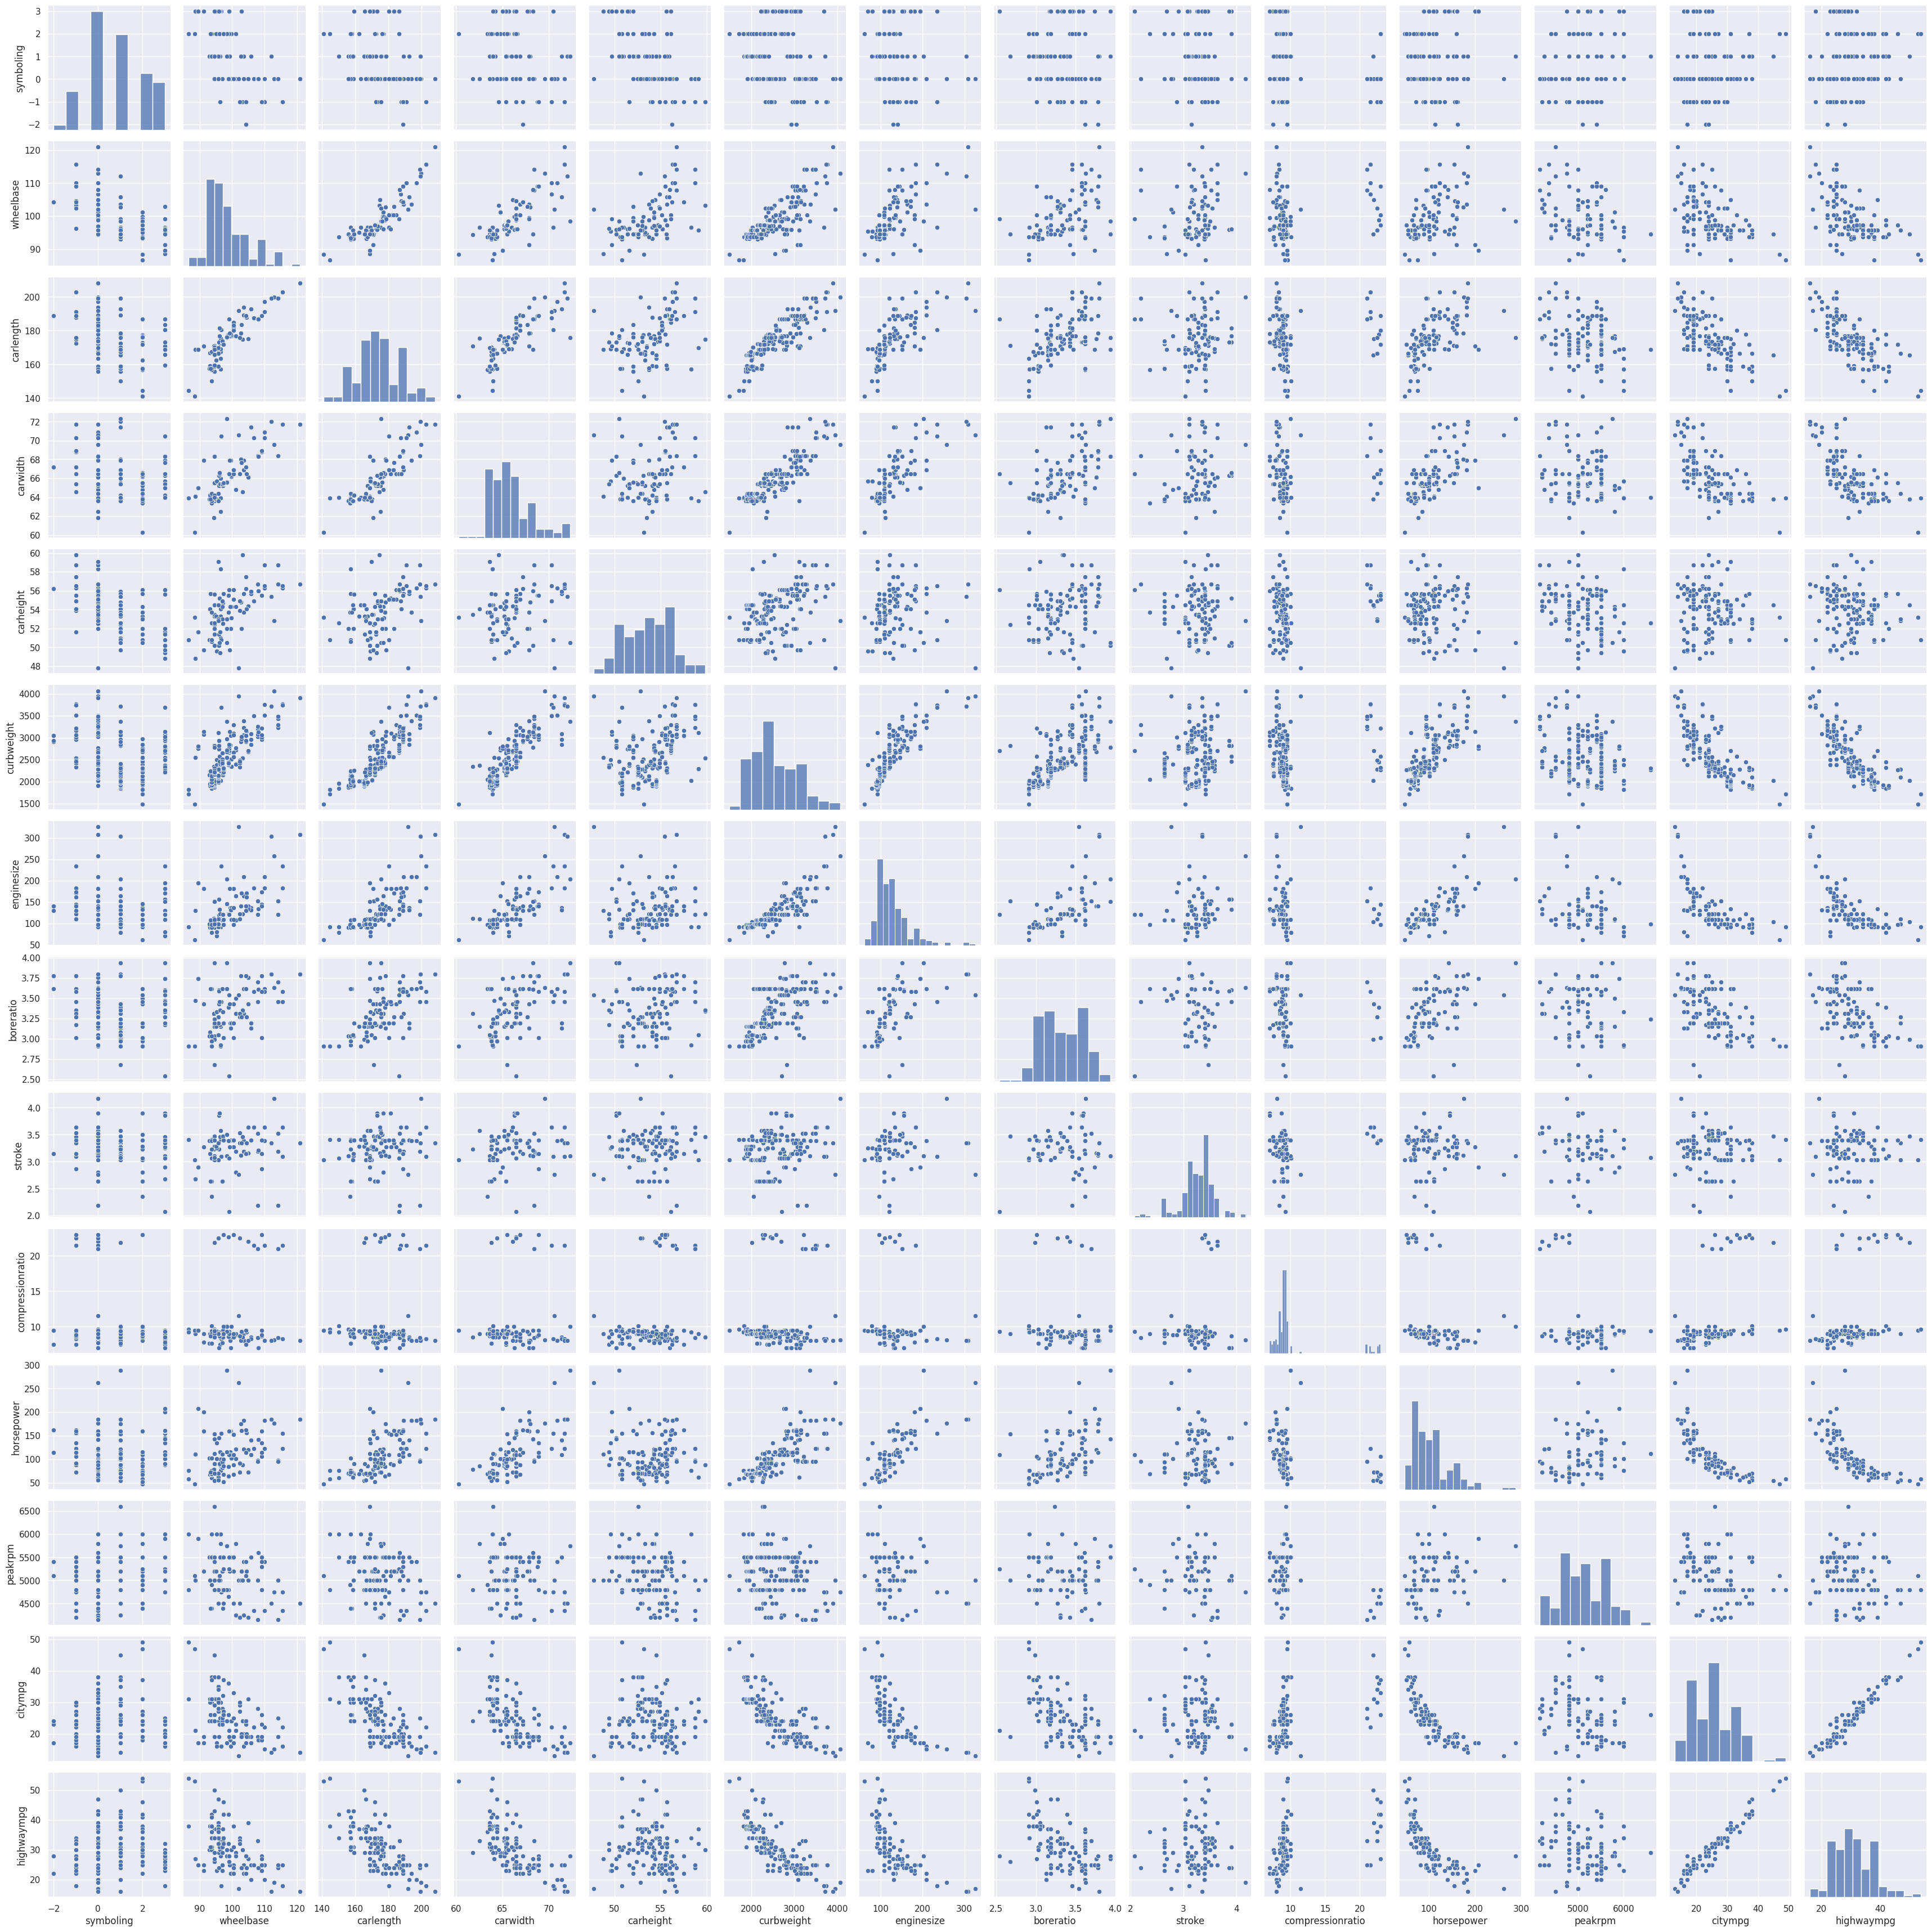

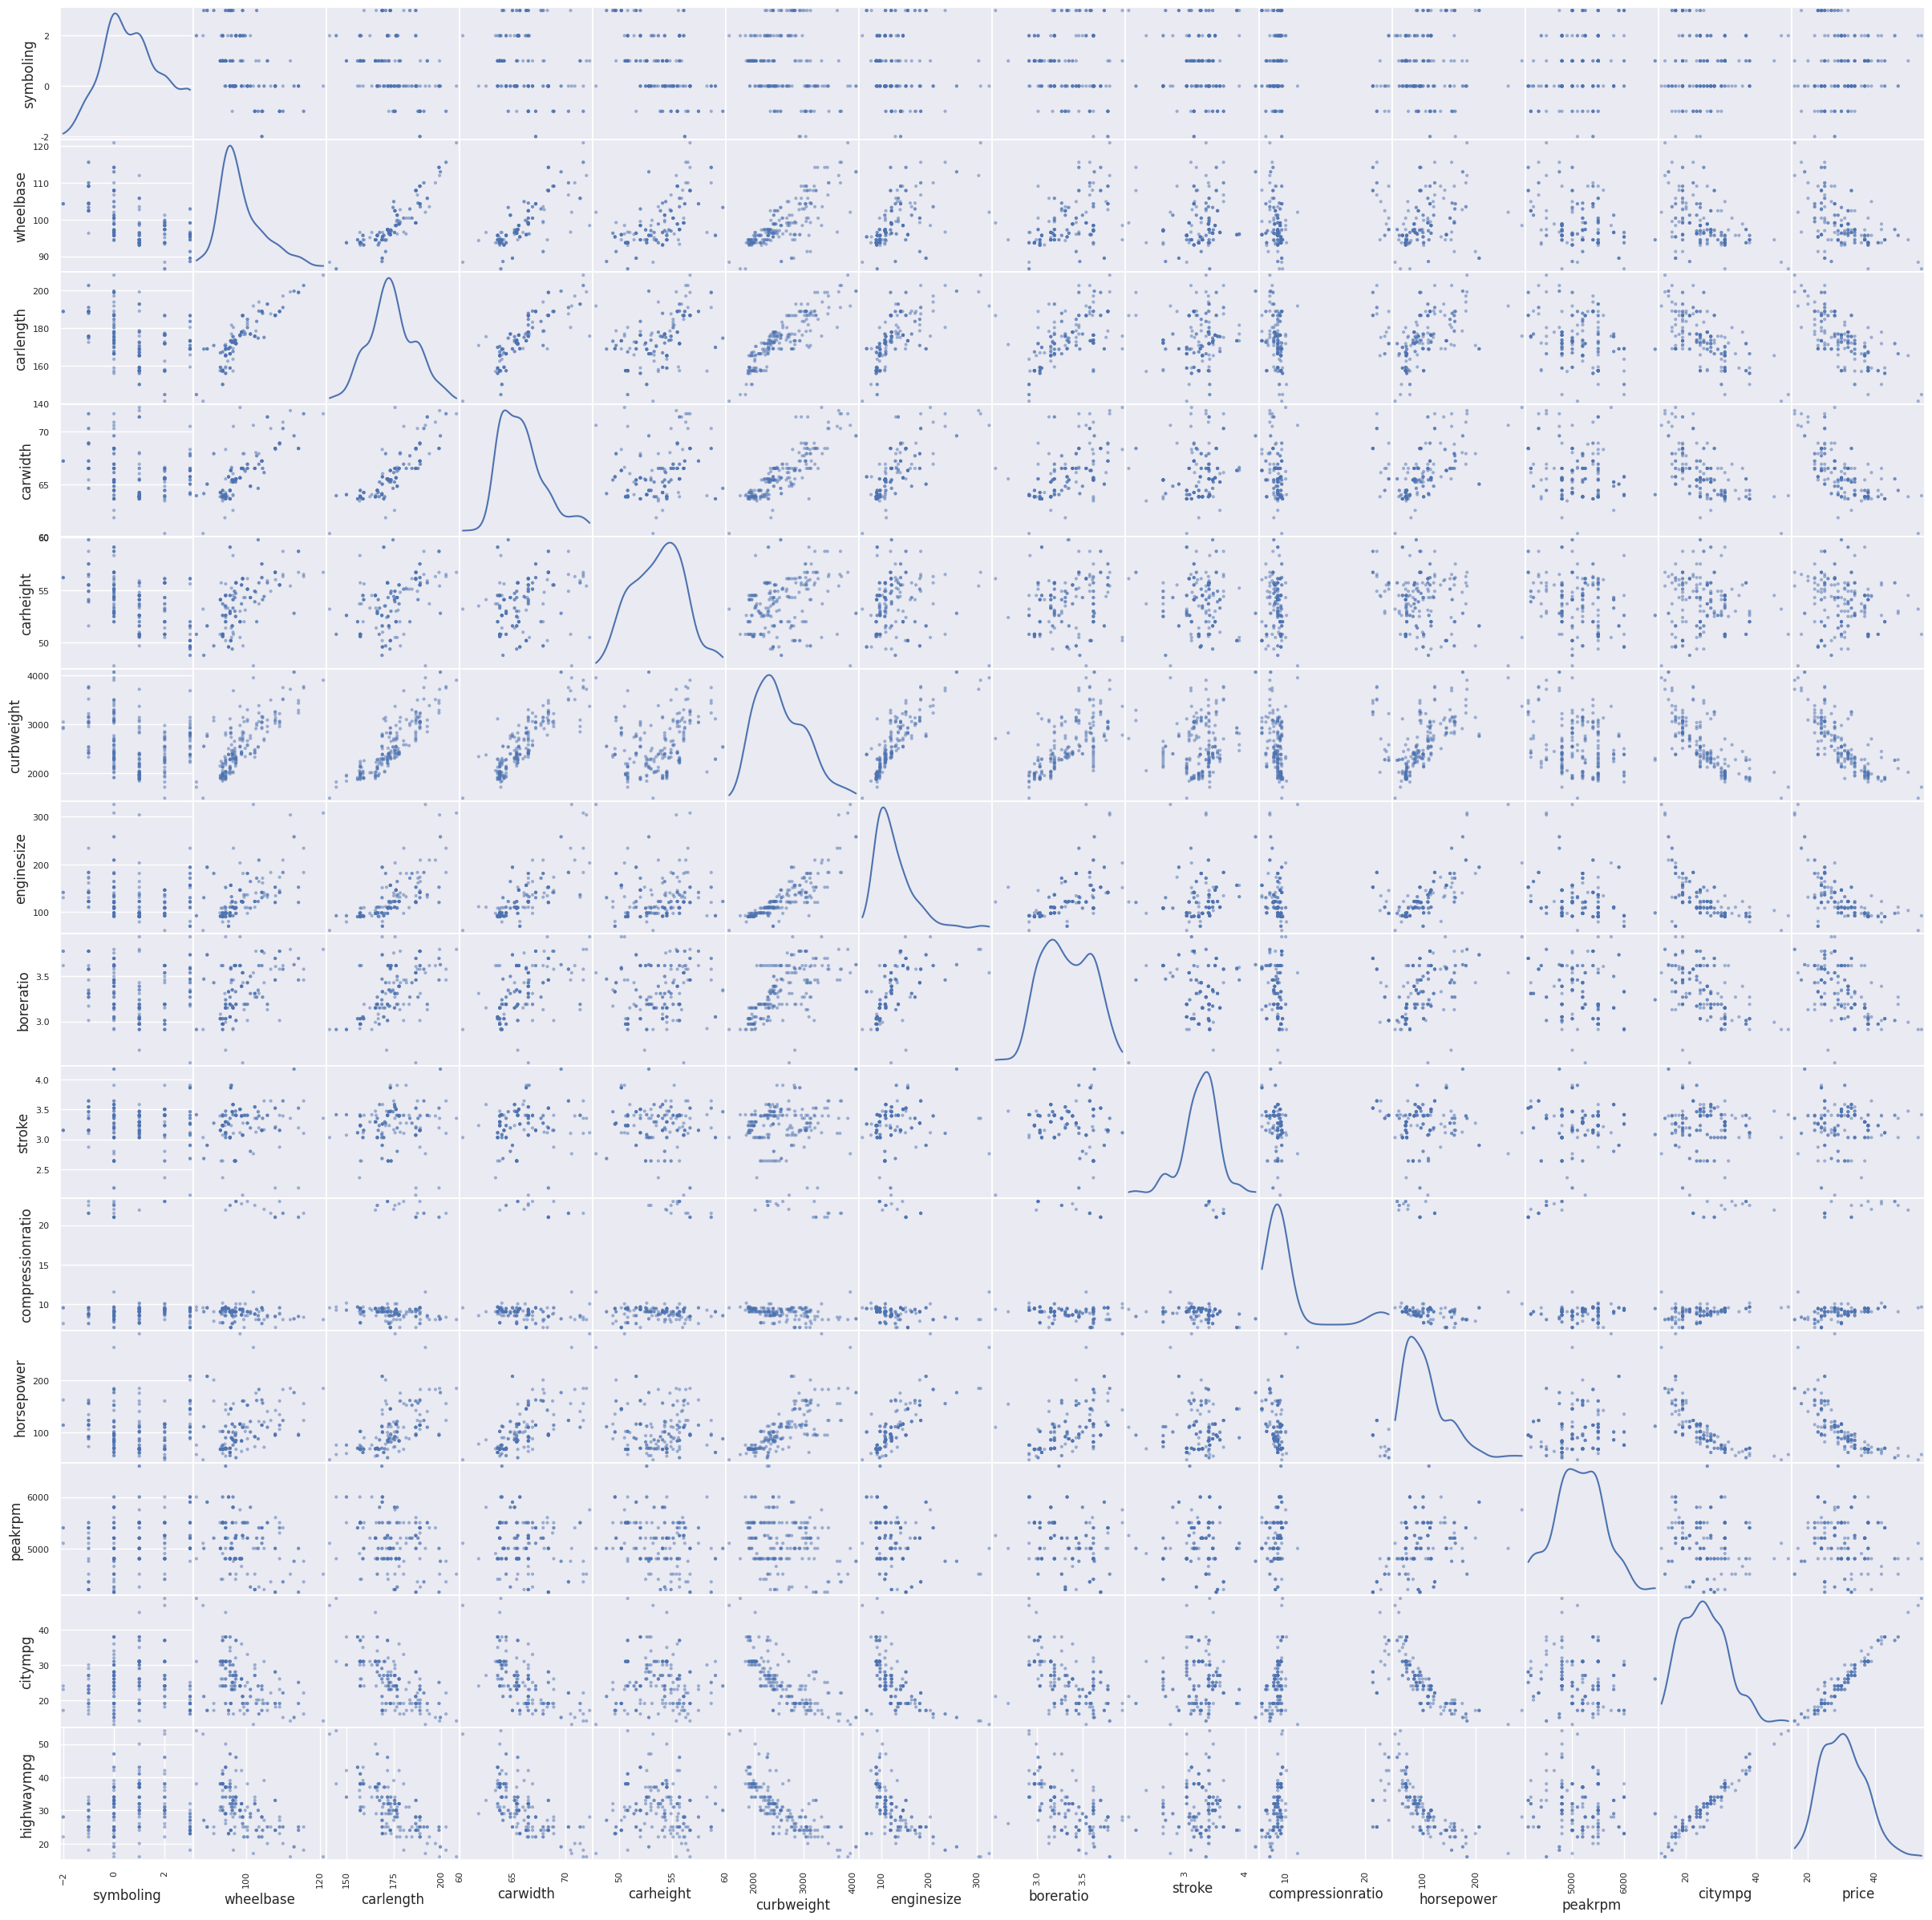

<Axes: >

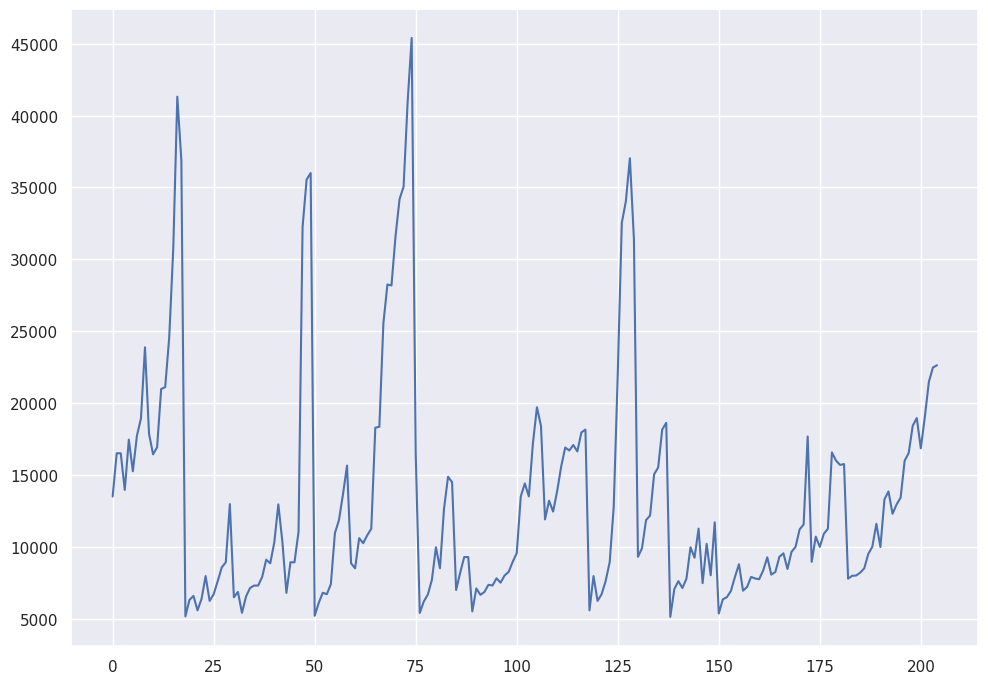

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from pandas.plotting import scatter_matrix
plt.rcParams["figure.figsize"] = [16,9]
sns.set(style="darkgrid")
sns.pairplot(data=X)
scatter_matrix(X, alpha=0.5, figsize=(30,30), diagonal='kde',grid='true')
sns.set(rc={'figure.figsize': (11.7,8.27)})
sns.distplot(Y, bins=30)
plt.show()
Y.plot()

In [ ]:
x = df.drop(['price', 'car_ID'], axis=1).copy()

print(x['doornumber'].value_counts())

x['doornumber'] = x['doornumber'].replace({"four": 4, "two": 2})

x['cylindernumber'] = x['cylindernumber'].replace({
    "four": 4,
    "six": 6,
    "five": 5,
    "eight": 8,
    "two": 2,
    "twelve": 12,
    "three": 3
})


doornumber
four    115
two      90
Name: count, dtype: int64


/tmp/ipykernel_5231/2907463163.py:5: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  x['doornumber'] = x['doornumber'].replace({"four": 4, "two": 2})
/tmp/ipykernel_5231/2907463163.py:7: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  x['cylindernumber'] = x['cylindernumber'].replace({


In [ ]:
cat=x.select_dtypes(include=['object']).copy(deep='fales')

In [ ]:
Name = cat.CarName.copy()
Temp = Name.str.split(pat=" ", expand=True)
Temp = Temp[0]

x.CarName = Temp
cat.CarName = Temp

In [ ]:
x["CarName"] = x["CarName"].replace({
    "maxda": "mazda",
    "porcshe": "porsche",
    "Nissan": "nissan",
    "vokswagen": "volkswagen",
    "toyouta": "toyota",
    "vw": "volkswagen"
})

In [ ]:
L = x.copy(deep=True)
L = pd.get_dummies(L, columns=cat.columns)

In [ ]:
df.head(6)

,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,...,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
0,1,3,alfa-romero giulia,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495.0
1,2,3,alfa-romero stelvio,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500.0
2,3,1,alfa-romero Quadrifoglio,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500.0
3,4,2,audi 100 ls,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950.0
4,5,2,audi 100ls,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450.0
5,6,2,audi fox,gas,std,two,sedan,fwd,front,99.8,...,136,mpfi,3.19,3.40,8.5,110,5500,19,25,15250.0


In [ ]:
from sklearn.preprocessing import scale
Xs=scale(L)
DATA=pd.DataFrame(Xs)

In [ ]:
from sklearn.model_selection import train_test_split
X_train,X_test,Y_train,Y_test=train_test_split(Xs,Y,test_size=0.3,random_state=42)

In [ ]:
from sklearn.linear_model import LinearRegression
coef=LinearRegression()
coef.fit(X_train,Y_train)

LinearRegression()

In [ ]:
from sklearn.metrics import mean_squared_error, r2_score

Y_pred = coef.predict(X_test)


print('Coefficients: \n', coef.coef_)

print("Mean squared error: %.2f"% mean_squared_error(Y_test, Y_pred))

print("Variance score(R^2): %.2f" % r2_score(Y_test, Y_pred))


Coefficients: 
 [-2.60765218e+02  2.55306983e+02  4.57124067e+02 -6.22344324e+02
  1.45991440e+03 -3.24422006e+02  2.12589415e+03 -8.01668557e+02
  4.09331713e+03 -1.01953369e+03 -7.72707088e+01  4.92266569e+02
  2.50591263e+02  8.12371780e+02  7.05080987e+02 -2.64509963e+02
  1.62591479e+02  2.48609633e+02  1.67049907e+03  1.59375307e+03
 -3.38514618e+02 -5.70831416e+02 -1.63504396e+02 -2.97111123e+01
  3.41641533e+02 -3.17311162e+02 -1.67248172e+01 -7.84341873e+02
 -4.86295716e+02 -1.19396595e+02 -5.54235113e+02  3.75263087e+02
  9.52461993e+02 -2.29976243e+02  3.64668952e+02 -2.45117632e+02
 -5.07321186e+02 -1.15784650e+02  3.58723690e+02 -2.99101284e+02
  2.99101284e+02 -4.86160264e+02  4.86160264e+02  5.52920765e+02
  5.89974559e+02 -1.12278908e+02 -1.21514759e+02 -2.85950805e+02
  2.10195605e+02  8.63987475e+01 -1.77286618e+02 -4.23571243e+02
  4.23571243e+02  3.43555629e+01  3.04613462e+01 -1.14609303e+02
 -7.69099378e+01 -2.56468007e+01 -3.03539637e+02  9.53102634e+02
 -3.50628